# 01 · Data quality: what can be trusted, and the clean subset

Before any "finding", this notebook settles what the arrival data can and cannot
support. It reads `analysis/data/analysis.duckdb` (built by `build_dataset.py`
from the raw 511 pings and the versioned GTFS schedules) and establishes:

1. **Coverage** over time and the collection gaps.
2. **Feed-health days**: windows where 511 kept sending vehicles but with stale
   positions. These must be masked or they dominate every "anomaly".
3. **Per-arrival quality**: the closest-approach distance tells us whether a
   computed arrival time means anything.
4. **Validation** against 511's own `stop_observations` (an independent source).
5. The **`clean` view** every later notebook starts from.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from common import q, connect, STATION_ORDER
from viz import BLUE, ORANGE, AQUA, RED, MUTED, SEQ, DIV, DIR_COLOR, note

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
con = connect()
qq = lambda s: q(s, con)

## 1. What the raw table holds

In [2]:
qq("""select count(*) arrivals, count(distinct date) service_days, min(date) first_day, max(date) last_day,
            count(distinct trip_id) train_numbers, count(distinct stop_id) platforms from arrivals""")

,arrivals,service_days,first_day,last_day,train_numbers,platforms
0,729538,419,2025-08-10,2026-10-22,185,58


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


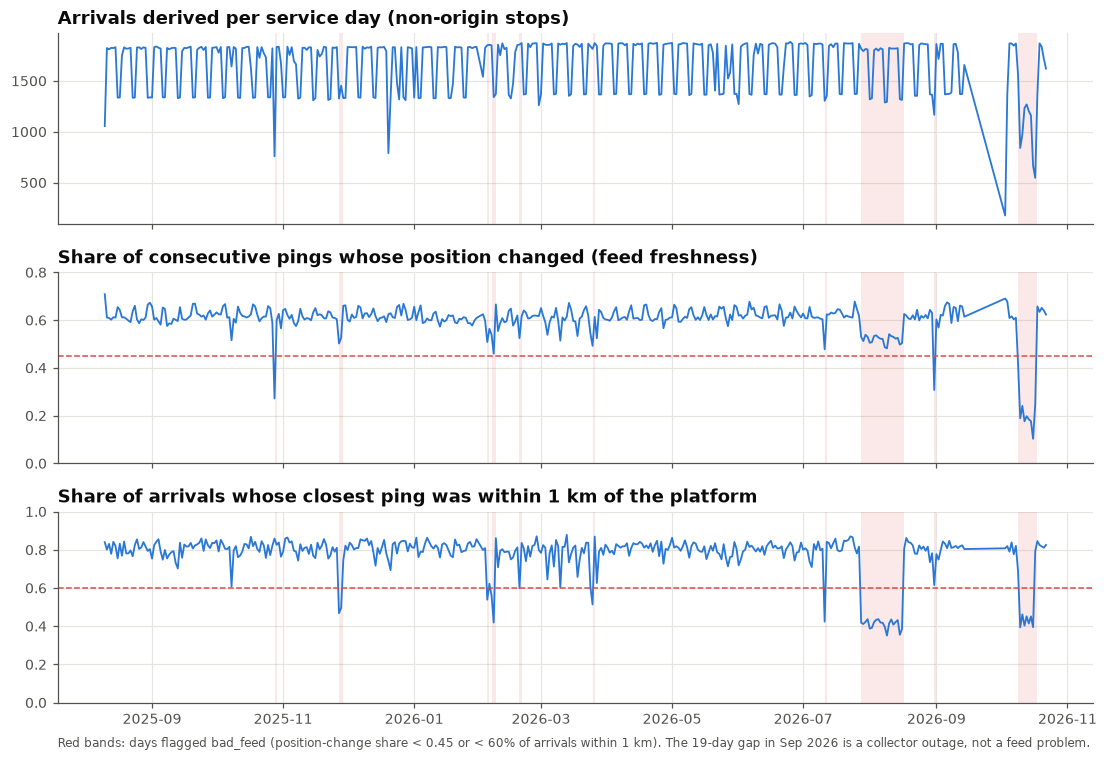

In [3]:
fd = qq("select * from feed_days order by date")
fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
axes[0].plot(fd.date, fd.arrivals, color=BLUE, lw=1.2)
axes[0].set_title("Arrivals derived per service day (non-origin stops)")
axes[1].plot(fd.date, fd.pos_change_share, color=BLUE, lw=1.2)
axes[1].axhline(0.45, color=RED, lw=1, ls="--"); axes[1].set_ylim(0, 0.8)
axes[1].set_title("Share of consecutive pings whose position changed (feed freshness)")
axes[2].plot(fd.date, fd.near1k, color=BLUE, lw=1.2)
axes[2].axhline(0.60, color=RED, lw=1, ls="--"); axes[2].set_ylim(0, 1)
axes[2].set_title("Share of arrivals whose closest ping was within 1 km of the platform")
for ax in axes:
    for _, r in fd[fd.bad_feed].iterrows():
        ax.axvspan(r.date, r.date + pd.Timedelta(days=1), color=RED, alpha=0.12, lw=0)
note(axes[2], "Red bands: days flagged bad_feed (position-change share < 0.45 or < 60% of arrivals within 1 km). "
              "The 19-day gap in Sep 2026 is a collector outage, not a feed problem.")
plt.tight_layout(); plt.show()

Two multi-day windows stand out, 2026-07-28 → 08-16 and 2026-10-10 → 10-17, plus a
scatter of single days (holidays with reduced service also show lower vehicle counts
but are not flagged unless positions were stale). The dashed lines are the thresholds
used by `common.py`.

In [4]:
fd[fd.bad_feed][["date", "dow", "vehicles_per_poll", "pos_change_share", "near1k", "arrivals"]].round(2)

,date,dow,vehicles_per_poll,pos_change_share,near1k,arrivals
79,2025-10-28,2,10.16,0.27,0.86,759
109,2025-11-27,4,5.47,0.50,0.47,1326
110,2025-11-28,5,5.91,0.53,0.50,1453
176,2026-02-04,3,9.19,0.51,0.54,1851
178,2026-02-06,5,9.04,0.54,0.56,1850
179,2026-02-07,6,5.70,0.46,0.42,1341
191,2026-02-19,4,9.78,0.52,0.60,1857
225,2026-03-25,3,8.87,0.49,0.51,1815
333,2026-07-11,6,5.67,0.48,0.42,1304
350,2026-07-28,2,7.05,0.53,0.42,1816


## 2. Per-arrival quality: closest-approach distance

The arrival time is the timestamp of the ping nearest the platform. If that ping is
kilometres away the "arrival" is a guess. The distance distribution is bimodal: a
healthy day has ~80% of arrivals within 1 km.

In [5]:
d = qq("""select case when stop_rank=1 then 'origin' else 'other' end pos,
          case when dist_m<100 then '<100 m' when dist_m<300 then '100-300 m' when dist_m<1000 then '300 m-1 km'
               when dist_m<3000 then '1-3 km' else '>3 km' end bucket,
          count(*) n, round(median(delay_signed),2) med_delay, round(avg((delay_signed<-5)::int),3) early5,
          round(avg((delay_signed>4)::int),3) late4
          from arrivals where arrival_time<'24:' group by 1,2 order by 1, min(dist_m)""")
d

,pos,bucket,n,med_delay,early5,late4
0,origin,<100 m,30547,-35.08,0.980,0.000
1,origin,100-300 m,4189,-27.22,0.977,0.000
2,origin,300 m-1 km,23,-16.05,0.565,0.304
3,origin,1-3 km,9,-4.22,0.444,0.333
4,origin,>3 km,14,-16.13,0.714,0.000
5,other,<100 m,202480,0.85,0.001,0.069
6,other,100-300 m,124360,0.82,0.000,0.078
7,other,300 m-1 km,212568,-0.02,0.000,0.071
8,other,1-3 km,126518,-0.10,0.001,0.063
9,other,>3 km,27514,-1.18,0.026,0.058


Beyond 1 km the median delay goes negative and the early-by-more-than-5-minutes
share jumps: these are stale positions scored against the wrong moment. Origin stops
are a different problem entirely (the train sits at the platform for up to an hour,
so its "closest approach" is whenever it first reported), so they are dropped.

**Delay precision is one minute**: 511's `RecordedAtTime` has the same seconds for
every ping of a train in a day, so delays are quantised (-1.1, -0.1, 0.9 …). Nothing
below ~2 minutes is individually meaningful; aggregates are fine.

## 3. The destination stop is never observed

511 names the *next* stop; after the penultimate stop the train's next stop becomes
the terminal and the feed keeps naming the penultimate stop until the train parks.
So trips to Tamien end at San Jose Diridon in our data, and trips to San Francisco
end at 22nd Street. "Delay at the end of the trip" below always means the last
*observed* stop.

In [6]:
qq("""select case when stop_rank=n_stops then 'final stop' when stop_rank=n_stops-1 then 'penultimate' else 'earlier' end k,
          count(*) n from arrivals group by 1 order by 1""")

,k,n
0,earlier,691284
1,penultimate,38254


## 4. Validation against 511's own observed arrivals

The monthly 511 archives carry `stop_observations.txt`, an independent record of
arrivals produced by 511's own arrival detector. Matching on (date, train, stop):

In [7]:
con.execute("""create or replace temp macro hms(s) as (split_part(s,':',1)::int*3600 + split_part(s,':',2)::int*60 + split_part(s,':',3)::int)/60.0""")
con.execute("""create or replace temp view obs511 as
  select strptime(service_date,'%Y%m%d')::date date, train trip_id, to_stop_id stop_id, try_cast(stop_sequence as int) seq,
         hms(observed_arrival_time) - hms(scheduled_arrival_time) d511
  from stop_observations where try_cast(stop_sequence as int)>1 and length(observed_arrival_time)=8 and length(scheduled_arrival_time)=8""")
agree = qq("""select count(*) n, round(corr(d511, delay_signed),3) r, round(avg((abs(d511-delay_signed)<=2)::int),3) within_2min,
   round(median(d511-delay_signed),2) median_diff, round(avg((d511>4)::int),3) late4_511, round(avg((delay_signed>4)::int),3) late4_gps
   from clean join obs511 using(date, trip_id, stop_id) where d511 between -30 and 300""")
agree

,n,r,within_2min,median_diff,late4_511,late4_gps
0,435855,0.957,0.966,-0.1,0.087,0.072


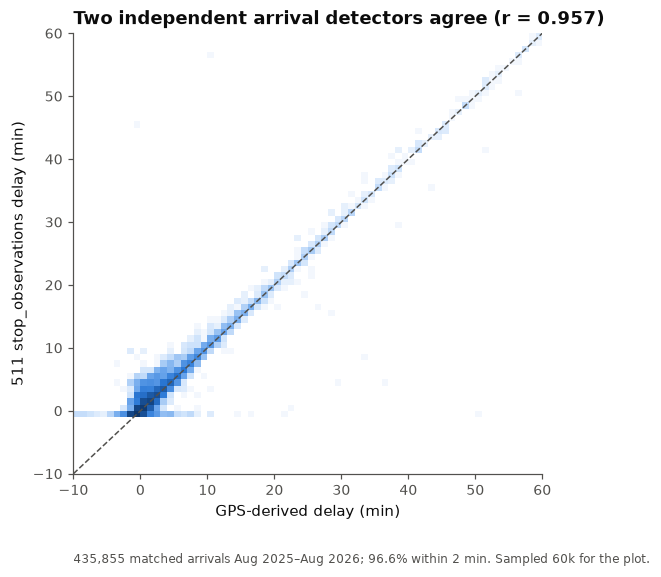

In [8]:
m = qq("""select delay_signed gps, d511 from clean join obs511 using(date, trip_id, stop_id)
          where d511 between -10 and 60 and delay_signed between -10 and 60 using sample 60000""")
fig, ax = plt.subplots(figsize=(5.5, 5.2))
from matplotlib.colors import LogNorm
h = ax.hist2d(m.gps, m.d511, bins=70, range=[[-10, 60], [-10, 60]], cmap=SEQ, cmin=1, norm=LogNorm())
ax.plot([-10, 60], [-10, 60], color=MUTED, lw=1, ls="--")
ax.set_xlabel("GPS-derived delay (min)"); ax.set_ylabel("511 stop_observations delay (min)")
ax.set_title("Two independent arrival detectors agree (r = %.3f)" % agree.r[0]); ax.grid(False)
note(ax, f"{agree.n[0]:,} matched arrivals Aug 2025–Aug 2026; {agree.within_2min[0]:.1%} within 2 min. Sampled 60k for the plot.")
plt.show()

Agreement is high (r ≈ 0.96, 97% within two minutes). 511 flags slightly more
arrivals as > 4 min late than we do; station-level comparisons in notebook 02 show
that a couple of stations differ systematically between the two detectors, which is a
reason to treat station-level *medians* with some care even when the overall picture
is solid.

## 5. Why masking matters: what the two bad windows look like unmasked

The production pipeline clamps delay at 0 and keeps every arrival regardless of
distance. Under those rules the October window looks like the worst week of the year
and the August window looks like the best fortnight, and both are artefacts.

In [9]:
qq("""select case when date between '2026-07-28' and '2026-08-16' then 'Aug 2026 window'
                 when date between '2026-10-10' and '2026-10-17' then 'Oct 2026 window' else 'all other weekdays' end w,
          count(distinct date) ndays, round(count(*)*1.0/count(distinct date)) arrivals_per_day,
          round(avg((delay_signed>4)::int),3) late4_unmasked, round(avg((dist_m>=1000)::int),3) share_far_from_platform
   from arrivals where stop_rank>1 and arrival_time<'24:' and isodow(date)<=5 group by 1 order by 1""")

,w,ndays,arrivals_per_day,late4_unmasked,share_far_from_platform
0,Aug 2026 window,14,1811.0,0.044,0.576
1,Oct 2026 window,5,1105.0,0.102,0.574
2,all other weekdays,281,1801.0,0.067,0.196


## 6. The clean subset

`common.clean` = not origin, scheduled before midnight, closest ping within 1 km,
service day not flagged, real train numbers. This is what notebooks 02–04 use.

In [10]:
qq("""select count(*) arrivals, count(distinct date) ndays, round(avg(delay_signed),2) mean_delay, round(median(delay_signed),2) median_delay,
          round(quantile_cont(delay_signed,0.9),1) p90, round(avg(late4::int),3) share_late_4min, round(avg(late15::int),4) share_late_15min from clean""")

,arrivals,ndays,mean_delay,median_delay,p90,share_late_4min,share_late_15min
0,513158,380,1.36,0.8,3.8,0.072,0.0107


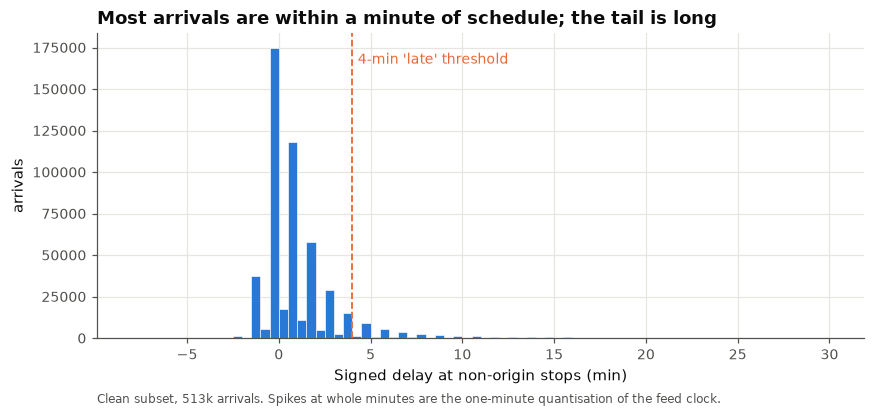

In [11]:
dd = qq("select delay_signed from clean where delay_signed between -8 and 30")
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.hist(dd.delay_signed, bins=np.arange(-8, 30.5, 0.5), color=BLUE, edgecolor="white", lw=0.4)
ax.axvline(4, color=ORANGE, lw=1.2, ls="--"); ax.text(4.3, ax.get_ylim()[1]*0.9, "4-min 'late' threshold", color=ORANGE, fontsize=9)
ax.set_xlabel("Signed delay at non-origin stops (min)"); ax.set_ylabel("arrivals")
ax.set_title("Most arrivals are within a minute of schedule; the tail is long")
note(ax, "Clean subset, 513k arrivals. Spikes at whole minutes are the one-minute quantisation of the feed clock.")
plt.show()